In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))   # make `src` importable when running from notebooks/
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, roc_auc_score
from src.config import *
from src.utils import *
from src.experiments import CV, SCORING, PARAM_DISTS, N_ITER

# Training on the full train set
So far the models were trained on a balanced **subset of 5170 images** of the train set (`train_subset_ground_truth.csv`).
Here we use **all 15195 train images** and check whether more data improves the performance on the validation set (3796 images, already complete).

Features of the full train set are generated with `python -m src.generate_full_train`.

#### Load the features

In [2]:
train_full = pd.read_csv(BINARY_FEATURES_TRAIN_FULL_CSV)
train_subset = pd.read_csv(BINARY_FEATURES_TRAIN_CSV)
val = pd.read_csv(BINARY_FEATURES_VAL_CSV)

bundle = joblib.load(MODELS_DIR / "binary_svm_tuned_v1.joblib")   # model trained on the subset
feature_cols = bundle["feature_cols"]

X_full, y_full = train_full[feature_cols].values, train_full["label"].values
X_val, y_val = val[feature_cols].values, val["label"].values

print("Train subset:", train_subset.shape, "| labels:", train_subset["label"].value_counts().to_dict())
print("Train full:  ", train_full.shape, "| labels:", train_full["label"].value_counts().to_dict())
print("Validation:  ", val.shape, "| labels:", val["label"].value_counts().to_dict())
print("NaN / inf in train full:", train_full[feature_cols].isna().sum().sum(),
      np.isinf(train_full[feature_cols].values).sum())

Train subset: (5170, 232) | labels: {1: 2670, 0: 2500}
Train full:   (15195, 232) | labels: {0: 7725, 1: 7470}
Validation:   (3796, 232) | labels: {0: 1931, 1: 1865}
NaN / inf in train full: 0 0


Sanity check: the subset images are part of the full set, and their features must be identical (same preprocessing and feature extraction).

In [3]:
common = train_full.set_index("filename").loc[train_subset["filename"], feature_cols]
max_diff = (common.values - train_subset[feature_cols].values).__abs__().max()
print(f"Subset images found in full set: {len(common)} / {len(train_subset)} | max feature difference: {max_diff:.2e}")

Subset images found in full set: 5170 / 5170 | max feature difference: 0.00e+00


Subtype distribution: the subset capped some "others" subtypes at 500 images, the full set keeps all of them.

In [4]:
subtype = lambda df: df["filename"].str.replace(r"\d+\.jpg$", "", regex=True)
pd.DataFrame({
    "subset": subtype(train_subset).value_counts(),
    "full":   subtype(train_full).value_counts(),
    "val":    subtype(val).value_counts(),
}).fillna(0).astype(int)

,subset,full,val
filename,,,
ack,500,520,130
bcc,500,1993,498
bkl,500,1574,393
def,143,143,35
mel,500,2713,678
nev,2500,7725,1931
scc,376,376,94
vac,151,151,37


### Three versions of the SVM
- **A - subset**: the tuned SVM saved in `baseline-classification.ipynb` (trained on 5170 images).
- **B - full, same params**: same pipeline and hyperparameters as A, retrained on the 15195 images.
- **C - full, retuned**: hyperparameters searched again on the full set, with the same search space and 5-fold CV as in `baseline-classification.ipynb`.

#### How a model is trained
Each model is a pipeline of 2 steps, and `.fit(X, y)` trains both in order with the training images (X: one row of 230 features per image, y: 0 = nevus, 1 = others):
1. **StandardScaler**: computes the mean and std of each feature on the training images and rescales every feature to mean 0, std 1,
   so features with large values (e.g. colour means, 0-255) do not weigh more than small ones (e.g. histogram bins, 0-1).
2. **SVM (RBF kernel)**: each image is a point in a 230-dimensional space. The SVM finds the boundary that separates nevus from others
   with the largest margin. The RBF kernel lets this boundary be curved. Two hyperparameters control it:
   - **C**: how much a training image on the wrong side of the boundary is penalised (high C = fits the training images more closely).
   - **gamma**: how far the influence of each training image reaches (low gamma = smoother boundary).

To predict a new image, `.predict()` applies the same scaling (with the mean and std learnt on train) and checks on which side of the boundary it falls.

**Model B** below: `clone` copies model A with its hyperparameters but without what it learnt, and `.fit` trains it on the 15195 images.

In [5]:
model_a = bundle["model"]
model_b = clone(model_a).fit(X_full, y_full)   # clone keeps the hyperparameters, drops the fitted state

**Model C**: `RandomizedSearchCV` tries 40 random (C, gamma) pairs, evaluates each one with 5-fold CV on the 15195 training images
(200 trainings), keeps the pair with the highest mean balanced accuracy and finally retrains the model with it on all 15195 images (`best_estimator_`).
The validation set is not used in this search.

In [6]:
search = RandomizedSearchCV(
    clone(model_a), PARAM_DISTS["SVM (RBF)"], n_iter=N_ITER["SVM (RBF)"],
    scoring=SCORING, refit="balanced_accuracy", cv=CV, n_jobs=-2, random_state=RANDOM_STATE,
)
search.fit(X_full, y_full)
model_c = search.best_estimator_

r, i = search.cv_results_, search.best_index_
print("Subset params:", bundle["best_params"])
print("Full params:  ", search.best_params_)
print("5-fold CV on full train:", {m: f"{r[f'mean_test_{m}'][i]:.3f} ± {r[f'std_test_{m}'][i]:.3f}" for m in SCORING})

Subset params: {'svc__C': np.float64(11.290133559092672), 'svc__gamma': np.float64(0.0020914981329035616)}
Full params:   {'svc__C': np.float64(30.634622106220824), 'svc__gamma': np.float64(0.0011756010900231862)}
5-fold CV on full train: {'accuracy': '0.831 ± 0.007', 'balanced_accuracy': '0.831 ± 0.007', 'sensitivity': '0.827 ± 0.015', 'specificity': '0.835 ± 0.007', 'auc': '0.907 ± 0.008'}


#### Evaluation on the validation set

In [7]:
def val_metrics(model):
    y_pred = model.predict(X_val)
    scores = model.decision_function(X_val)   # > 0 means "others"
    return {
        "accuracy":          accuracy_score(y_val, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, y_pred),
        "sensitivity":       recall_score(y_val, y_pred, pos_label=1),
        "specificity":       recall_score(y_val, y_pred, pos_label=0),
        "auc":               roc_auc_score(y_val, scores),
    }, y_pred, scores

models = {
    "A - subset (5170)":          model_a,
    "B - full, same params":      model_b,
    "C - full, retuned":          model_c,
}
results = {name: val_metrics(m) for name, m in models.items()}

comparison = pd.DataFrame({name: res[0] for name, res in results.items()}).T.round(3)
comparison.to_csv(RESULTS_DIR / "val_full_train_comparison.csv")
comparison

,accuracy,balanced_accuracy,sensitivity,specificity,auc
A - subset (5170),0.820,0.819,0.802,0.837,0.896
"B - full, same params",0.841,0.841,0.838,0.844,0.919
"C - full, retuned",0.842,0.842,0.838,0.845,0.918


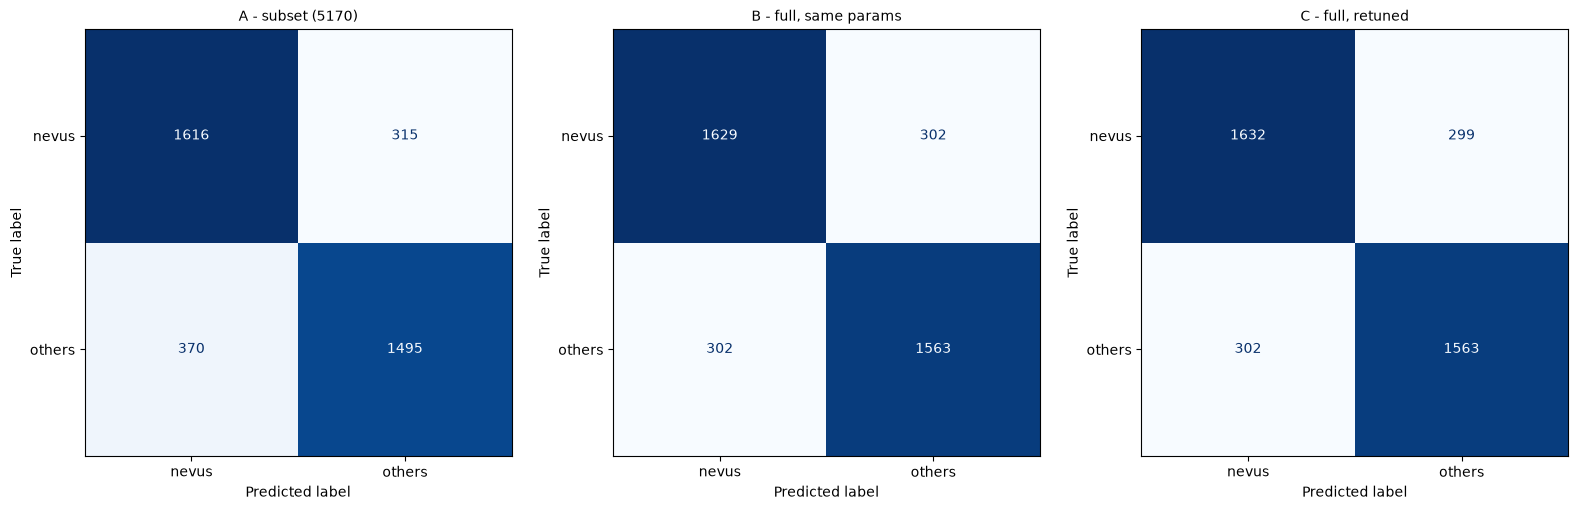

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, (_, y_pred, _)) in zip(axes, results.items()):
    plot_confusion(ax, y_val, y_pred, name)
plt.tight_layout()
plt.show()

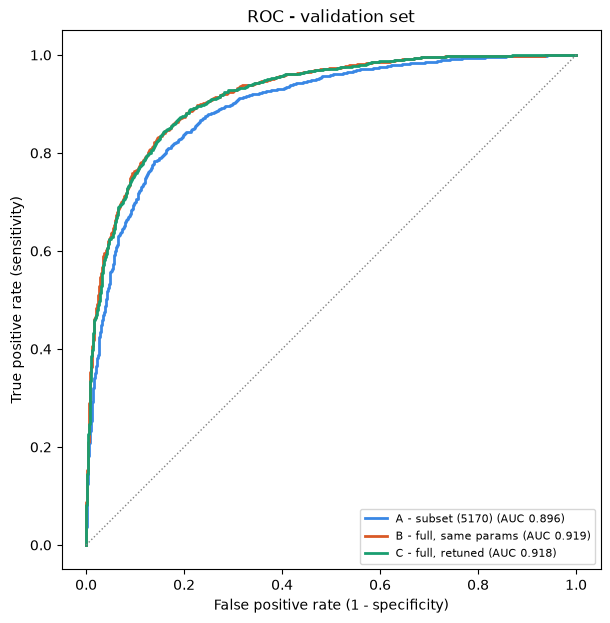

In [9]:
colors = ["#3987e5", "#d95926", "#199e70"]
fig, ax = plt.subplots(figsize=(7, 7))
for color, (name, (_, _, scores)) in zip(colors, results.items()):
    plot_roc(ax, y_val, scores, name, color)
finish_roc(ax, "ROC - validation set")
plt.show()

#### Save the model trained on the full set

In [10]:
best_full = max(["B - full, same params", "C - full, retuned"], key=lambda n: comparison.loc[n, "balanced_accuracy"])
model_best = models[best_full]
print("Saving:", best_full)

joblib.dump({
    "model":        model_best,                        # scaler + SVM, trained on the full train set
    "feature_cols": feature_cols,
    "params":       {k: v for k, v in model_best.get_params().items() if k in ("svc__C", "svc__gamma")},
    "val_scores":   comparison.loc[best_full].to_dict(),
}, MODELS_DIR / "binary_svm_full_v1.joblib")

Saving: C - full, retuned


['C:\\Users\\david\\OneDrive\\Documentos\\GitHub\\Project-1-CAD\\models\\binary_svm_full_v1.joblib']

#### Conclusions
- **Training on the full train set clearly improves the validation performance**: balanced accuracy goes from 0.819 (subset) to 0.841-0.842, and AUC from 0.896 to 0.918-0.919. Sensitivity improves the most (0.802 -> 0.838).
- **Retuning the hyperparameters barely matters** (B vs C differ by 0.001): the gain comes from the data, not from the hyperparameters.
- The 5-fold CV score on the full set (0.831) is *lower* than on the subset (0.858), but the validation score is *higher*. The subset capped the "others" subtypes (e.g. only 500 of 2713 mel and 500 of 1993 bcc), so its distribution differs from validation, and its CV score was optimistic. The full train set has the same subtype proportions as validation, so its CV estimate is much closer to the validation result.
- The model trained on the full set (C) is saved as `models/binary_svm_full_v1.joblib`.